In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from bidi.algorithm import get_display
import arabic_reshaper


In [2]:
df_br = pd.read_csv(r'D:\HVIA\New folder\Cottonil_project\COTTONIL\data\branches.csv')

In [3]:
print(f'the number of branches is {df_br["branch_id"].nunique()}')

the number of branches is 80


In [4]:
df_br.columns

Index(['branch_id', 'branch_name_ar', 'governorate_ar', 'city_ar',
       'address_ar', 'retail_location_type', 'opening_date'],
      dtype='object')

In [5]:
print(f'number of governorates is {df_br["governorate_ar"].nunique()}')

number of governorates is 21


In [7]:
df_br.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   branch_id             80 non-null     object
 1   branch_name_ar        80 non-null     object
 2   governorate_ar        80 non-null     object
 3   city_ar               80 non-null     object
 4   address_ar            80 non-null     object
 5   retail_location_type  80 non-null     object
 6   opening_date          80 non-null     object
dtypes: object(7)
memory usage: 4.5+ KB


In [11]:
df_br['opening_date'] = pd.to_datetime(df_br['opening_date'], format='%m/%d/%Y')

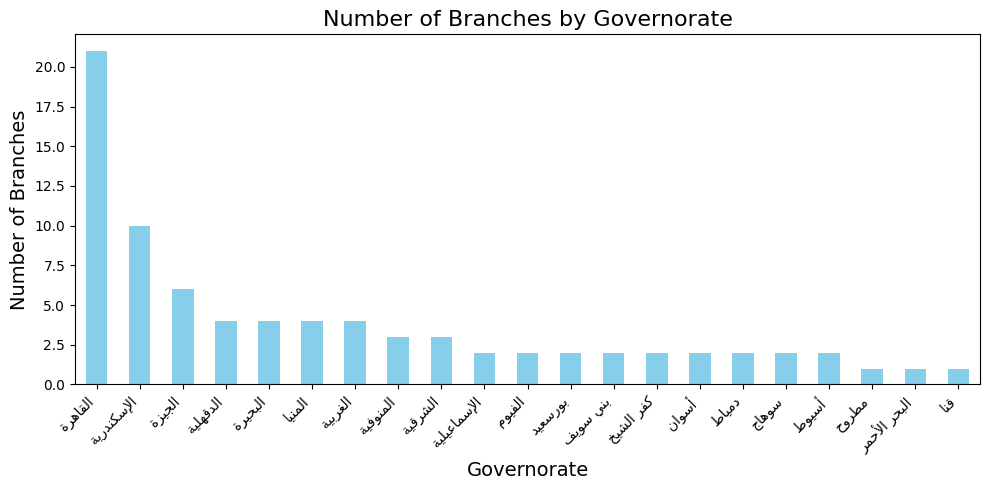

In [6]:
dic_br = df_br['governorate_ar'].value_counts()

dic_br.index = [
    get_display(arabic_reshaper.reshape(str(name)))
    for name in dic_br.index
]

dic_br.plot(kind='bar', figsize=(10, 5), color='skyblue')

plt.title('Number of Branches by Governorate', fontsize=16)
plt.xlabel('Governorate', fontsize=14)
plt.ylabel('Number of Branches', fontsize=14)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [12]:
df_br['opening_date'].describe()

count                     80
mean     2019-09-01 09:36:00
min      2018-11-06 00:00:00
25%      2019-04-27 06:00:00
50%      2019-08-17 12:00:00
75%      2020-01-22 12:00:00
max      2020-08-29 00:00:00
Name: opening_date, dtype: object

In [ ]:
branches = pd.read_csv(r'D:\HVIA\New folder\Cottonil_project\COTTONIL\data\branches.csv')
orders = pd.read_csv(r'D:\HVIA\New folder\Cottonil_project\COTTONIL\data\sales_order_items.csv')
returns = pd.read_csv(r'D:\HVIA\New folder\Cottonil_project\COTTONIL\data\sales_returns.csv')

In [16]:
print(f'branches columns: {branches.columns}')
print(f'orders columns: {orders.columns}')
print(f'returns columns: {returns.columns}')

branches columns: Index(['branch_id', 'branch_name_ar', 'governorate_ar', 'city_ar',
       'address_ar', 'retail_location_type', 'opening_date'],
      dtype='object')
orders columns: Index(['sales_line_id', 'sales_order_id', 'order_date', 'branch_id', 'sku_id',
       'product_id', 'quantity', 'unit_price_EGP', 'gross_line_EGP',
       'discount_line_EGP', 'net_line_EGP', 'unit_cost_EGP', 'margin_EGP'],
      dtype='object')
returns columns: Index(['return_id', 'sales_order_id', 'sales_line_id', 'return_date', 'sku_id',
       'return_quantity', 'refund_amount_EGP', 'reason', 'refund_method'],
      dtype='object')


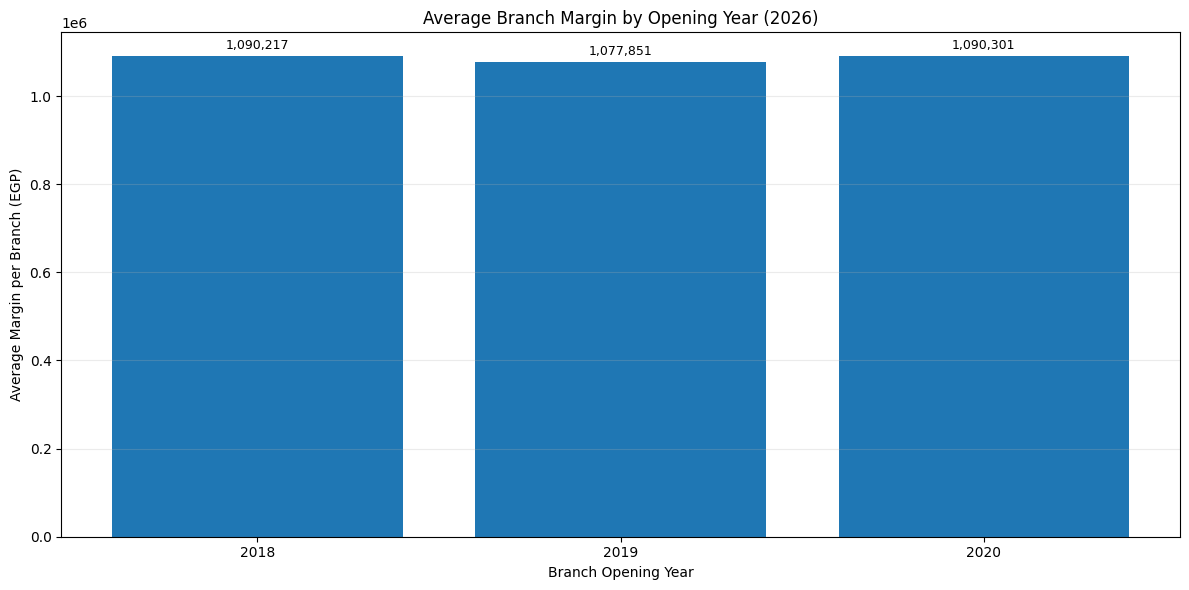

,opening_year,total_margin,branch_count,margin_per_branch
0,2018,10902173.87,10,1.090217e+06
1,2019,51736848.05,48,1.077851e+06
2,2020,23986612.82,22,1.090301e+06


In [17]:

import pandas as pd
import matplotlib.pyplot as plt



# 2. Remove returned orders
returned_order_ids = returns["sales_order_id"].dropna().unique()

orders_filtered = orders[
    ~orders["sales_order_id"].isin(returned_order_ids)
].copy()

# 3. Convert dates
orders_filtered["order_date"] = pd.to_datetime(
    orders_filtered["order_date"],
    errors="coerce"
)

branches["opening_date"] = pd.to_datetime(
    branches["opening_date"],
    errors="coerce"
)

# 4. Filter orders for 2026
orders_2026 = orders_filtered[
    orders_filtered["order_date"].dt.year == 2026
].copy()

# 5. Merge orders with branches
df = orders_2026.merge(
    branches[["branch_id", "branch_name_ar", "opening_date"]],
    on="branch_id",
    how="left",
    validate="many_to_one"
)

# 6. Extract branch opening year
df["opening_year"] = df["opening_date"].dt.year

# 7. Aggregate margin and count branches by opening year
margin_by_year = (
    df.groupby("opening_year")
    .agg(
        total_margin=("margin_EGP", "sum"),
        branch_count=("branch_id", "nunique")
    )
    .reset_index()
)

# 8. Calculate average margin per branch
margin_by_year["margin_per_branch"] = (
    margin_by_year["total_margin"]
    / margin_by_year["branch_count"]
)

# 9. Sort by opening year
margin_by_year = margin_by_year.sort_values("opening_year")

# 10. Plot column chart
plt.figure(figsize=(12, 6))

bars = plt.bar(
    margin_by_year["opening_year"].astype("Int64").astype(str),
    margin_by_year["margin_per_branch"]
)

plt.bar_label(
    bars,
    labels=[
        f"{value:,.0f}"
        for value in margin_by_year["margin_per_branch"]
    ],
    padding=3,
    fontsize=9
)

plt.title("Average Branch Margin by Opening Year (2026)")
plt.xlabel("Branch Opening Year")
plt.ylabel("Average Margin per Branch (EGP)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# 11. Display summary table
display(margin_by_year)


In [18]:
df = pd.read_csv('branch_performance.csv')
branch_performance = pd.merge(df ,branches[['branch_id', 'governorate_ar']], on='branch_id', how='left')

In [20]:
branch_performance.to_csv('branch_performance.csv', index=False)

In [21]:
branch_performance.columns

Index(['branch_id', 'branch_name_ar', 'Profit', 'Completed_Orders',
       'Returned_Orders', 'governorate_ar'],
      dtype='object')

In [22]:
orders.head()

,sales_line_id,sales_order_id,order_date,branch_id,sku_id,product_id,quantity,unit_price_EGP,gross_line_EGP,discount_line_EGP,net_line_EGP,unit_cost_EGP,margin_EGP
0,SL000000001,SO00000001,2018-10-19,BR010,SKU000662,PR0133,1,27.00,27.00,2.70,24.30,12.95,11.35
1,SL000000002,SO00000002,2018-10-19,BR047,SKU000532,PR0107,1,71.99,71.99,10.80,61.19,48.74,12.45
2,SL000000003,SO00000002,2018-10-19,BR047,SKU000374,PR0075,6,34.56,207.36,0.00,207.36,16.68,107.28
3,SL000000004,SO00000003,2018-10-19,BR013,SKU000602,PR0121,1,160.72,160.72,32.14,128.58,85.44,43.14
4,SL000000005,SO00000004,2018-10-19,BR029,SKU000370,PR0074,1,32.06,32.06,1.60,30.46,21.09,9.37


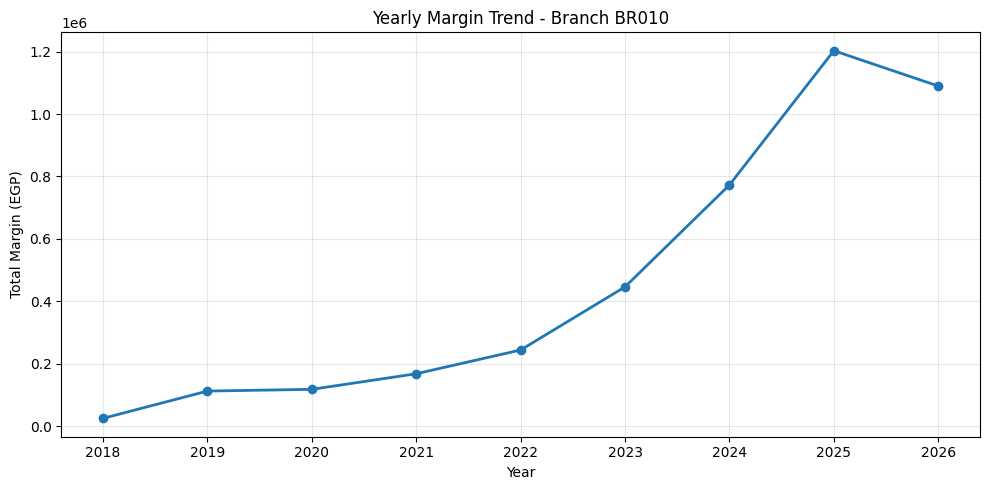

,year,margin_EGP
0,2018,25301.06
1,2019,112664.93
2,2020,118247.56
3,2021,168139.60
4,2022,244211.43
5,2023,446484.12
6,2024,772808.58
7,2025,1202845.45
8,2026,1089791.23


In [24]:

import pandas as pd
import matplotlib.pyplot as plt

# Load data if not already loaded
# Orders = pd.read_csv("Orders.csv")

# Prepare dates
orders["order_date"] = pd.to_datetime(
    orders["order_date"],
    errors="coerce"
)

orders["margin_EGP"] = pd.to_numeric(
    orders["margin_EGP"],
    errors="coerce"
)

# Input branch ID
branch_id = input("Enter Branch ID: ")

# Filter selected branch
branch_data = orders[
    (orders["branch_id"].astype(str) == branch_id.strip())
    & orders["order_date"].notna()
].copy()

if branch_data.empty:
    print("No data found for this Branch ID.")

else:
    # Extract year
    branch_data["year"] = branch_data["order_date"].dt.year

    # Calculate yearly margin
    yearly_margin = (
        branch_data.groupby("year")["margin_EGP"]
        .sum()
        .sort_index()
    )

    # Plot line chart
    plt.figure(figsize=(10, 5))

    plt.plot(
        yearly_margin.index,
        yearly_margin.values,
        marker="o",
        linewidth=2
    )

    plt.title(f"Yearly Margin Trend - Branch {branch_id}")
    plt.xlabel("Year")
    plt.ylabel("Total Margin (EGP)")
    plt.xticks(yearly_margin.index)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    display(yearly_margin.reset_index())
